In [1]:
!pip install poetry

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 307.6/307.6 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.6/413.6 kB 23.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.7/78.7 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 464.5/464.5 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.0/83.0 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 52.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 493.4/493.4 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 470.6/470.6 kB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 34.0 MB/s eta 0:00:00


In [2]:
!poetry init


This command will guide you through creating your pyproject.toml config.

Package name [content]:  
Version [0.1.0]:  
Description []:  
Author [None, n to skip]:  n
License []:  
Compatible Python versions [>=3.13]:  

Would you like to define your main dependencies interactively? (yes/no) [yes] 
        You can specify a package in the following forms:
          - A single name (requests): this will search for matches on PyPI
          - A name and a constraint (requests@^2.23.0)
          - A git url (git+https://github.com/python-poetry/poetry.git)
          - A git url with a revision         (git+https://github.com/python-poetry/poetry.git#develop)
          - A file path (../my-package/my-package.whl)
          - A directory (../my-package/)
          - A url (https://example.com/packages/my-package-0.1.0.tar.gz)
        
Package to add or search for (leave blank to skip): 

Would you like to define your development dependencies interactively? (yes/no) [yes] 
Package to add or 

In [3]:
!pip install langchain langgraph langchain-tavily

In [4]:
!pip install -U "langchain-openrouter"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.6/90.6 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 837.3/837.3 kB 55.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 463.6/463.6 kB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 91.3 MB/s eta 0:00:00
  Attempting uninstall: pydantic-core
    Found existing installation: pydantic_core 2.46.5
    Uninstalling pydantic_core-2.46.5:
      Successfully uninstalled pydantic_core-2.46.5
  Attempting uninstall: pydantic
    Found existing installation: pydantic 2.13.5
    Uninstalling pydantic-2.13.5:
      Successfully uninstalled pydantic-2.13.5


In [5]:
import os

os.environ["OPENROUTER_API_KEY"] = "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"
os.environ['TAVILY_API_KEY'] = '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'

In [ ]:
from langchain_core.tools import tool
from langchain_openrouter import ChatOpenRouter
from langchain_tavily import TavilySearch

@tool
def triple(num:float) -> float:
  """
  params: num -> float
  returns: the triple of the input number
  """
  return float(num)*3

tools = [TavilySearch(max_results=1),triple]

llm = ChatOpenRouter(model='auto').bind_tools(tools)

In [ ]:
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode

SYSTEM_PROMPT = """
You are a helpful assistant that can use tools to answer questions.
"""

def run_agent_reasoning(state:MessagesState)->MessagesState:
  """
  Run the agent reasoning node
  """
  response = llm.invoke([{"role":"system","content":SYSTEM_PROMPT},*state.messages])
  return{"messages":response}

tool_node = ToolNode(tools)


In [ ]:
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph,MessagesState,END

AGENT_REASON = "agent_reason"
ACT = "act"
LAST = -1

def should_continue(state:MessagesState)->str:
  if not state["messages"][LAST].tool_calls:
    return END
  return ACT

flow = StateGraph(MessagesState)

flow.add_node(AGENT_REASON,run_agent_reasoning)
flow.add_node(ACT,tool_node)

flow.set_entry_point(AGENT_REASON)

flow.add_conditional_edges(AGENT_REASON,should_continue,{
    END:END,
    ACT:ACT
})

flow.add_edge(ACT,AGENT_REASON)

app = flow.compile()
app.get_graph().draw_mermaid_png(output_file_path="flow.png")

b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x00\xcb\x00\x00\x00\xf9\x08\x02\x00\x00\x00\x06+V\xc2\x00\x00\x10\x00IDATx\x9c\xec\x9d\x07`\x13\xc7\xd2\xc7\xf7T-\xcb\xbdw\x8cM1\xdd\xf4\x1a\x08\x18B\x02$\xd4\xc0G\xf1\x0b!\xc4\xf4@\x02\x06\x12 \x01\x12 \xd4\xd0\x1e$\xf4\xd0{\x8f)\t\x1d\x831\xcd\x80\x0b\x06W\x8a{\x93lu\xe9\xf4\x8dt\xc6\x18\x9eM0\xe8\xa4\x93\xb4?\x14e\xb5\xb7w\x92u\x7f\xcd\xce\xce\xee\xcdq\xb4Z-\xc2`h\x83\x850\x18:\xc1\n\xc3\xd0\x0bV\x18\x86^\xb0\xc20\xf4\x82\x15\x86\xa1\x17\xac0\x0c\xbdp\x10F\xcf\xb3G\x8a\xc7w\xc4\x85yJ\x85TC\xaa\xb5\xa4\xe6\xd5\xcd,-"\x89Wj\x08-\xc1"\xb4\x95\x9ai\t-\x8b \xb4d\xa5&,\xad\x16\xf6"\xb4\x88 \x10\xf9rGh\x8a\xe0`\xaf\x85\x89\xe0\x80\x84\xee-*\x1f\x81:\xac\xaeuU1%\xbe-\x9b\xcdE\xb6v\x1c\xff\x10\xdb\xa6\x9d\x1c\x10#!\xac<\x1e\x96t\xbd\xec\xd6\xf9\xc2\xd2"5\x9cD8[\\>\x9b\xcbc\xb1\x08\xa4Q\xbfr\x9eub"_\xfd\xa2\xe0\xb4\x13\xafV\xb2t\x02\xa9\\C\xb0tr!t\xf2\x80\xff\xca\xeb\t\xaa\xf8\xbf\nc!\xbd\xee\xd0ko\x04\x9f\x86\x84\x1d\xaa:K<[\x8eJA\xc2C)\'5\x1a\xa

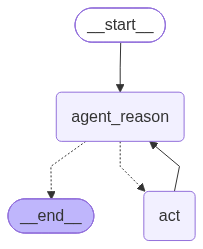

In [ ]:
from IPython.display import Image, display

png_bytes = app.get_graph().draw_mermaid_png()

display(Image(png_bytes))

In [ ]:
res = app.invoke({"messages":[HumanMessage(content="What is the waether in Tokyo? List it then triple it")]})
print(res["messages"][LAST].content)

AttributeError: 'dict' object has no attribute 'messages'

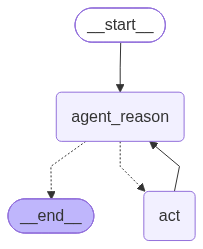

Here's the weather information for Tokyo:

- **Current temperature in Tokyo:** 22°C (cloudy with a chance of showers)
- **Tripled temperature:** 66°C

So, the current temperature in Tokyo is **22°C**, and when tripled, it becomes **66°C**.


In [ ]:
# ============================================================
# 1. IMPORTS
# ============================================================

from langchain_core.tools import tool
from langchain_openrouter import ChatOpenRouter
from langchain_tavily import TavilySearch

from langgraph.graph import StateGraph, MessagesState, END
from langgraph.prebuilt import ToolNode

from langchain_core.messages import HumanMessage

from IPython.display import Image, display


# ============================================================
# 2. DEFINE TOOLS
# ============================================================

@tool
def triple(num: float) -> float:
    """
    Triple the input number.

    Args:
        num: Number to triple.

    Returns:
        Three times the input number.
    """
    return float(num) * 3


# Tavily search tool
search_tool = TavilySearch(max_results=1)

tools = [
    search_tool,
    triple
]


# ============================================================
# 3. CREATE LLM
# ============================================================

llm = ChatOpenRouter(
    model="auto"
).bind_tools(tools)


# ============================================================
# 4. SYSTEM PROMPT
# ============================================================

SYSTEM_PROMPT = """
You are a helpful assistant that can use tools to answer questions.

When the user asks you to search for information:
1. Use the Tavily search tool.
2. Read the result.
3. If the user asks you to perform a calculation on the result,
   use the appropriate calculation tool.
4. Then provide the final answer.
"""


# ============================================================
# 5. AGENT REASONING NODE
# ============================================================

def run_agent_reasoning(state: MessagesState) -> MessagesState:
    """
    LLM reasoning node.

    The LLM receives the conversation history and decides
    whether it needs to call a tool or provide a final answer.
    """

    response = llm.invoke(
        [
            {
                "role": "system",
                "content": SYSTEM_PROMPT
            },
            *state["messages"]
        ]
    )

    return {
        "messages": [response]
    }


# ============================================================
# 6. TOOL NODE
# ============================================================

tool_node = ToolNode(tools)


# ============================================================
# 7. DECIDE WHETHER TO CONTINUE
# ============================================================

AGENT_REASON = "agent_reason"
ACT = "act"

LAST = -1


def should_continue(state: MessagesState) -> str:
    """
    Decide whether the agent should:

    - END → if the LLM didn't request a tool
    - ACT → if the LLM requested a tool
    """

    last_message = state["messages"][LAST]

    if not last_message.tool_calls:
        return END

    return ACT


# ============================================================
# 8. BUILD GRAPH
# ============================================================

flow = StateGraph(MessagesState)


# Add nodes
flow.add_node(
    AGENT_REASON,
    run_agent_reasoning
)

flow.add_node(
    ACT,
    tool_node
)


# Entry point
flow.set_entry_point(AGENT_REASON)


# Conditional edge after LLM reasoning
flow.add_conditional_edges(
    AGENT_REASON,
    should_continue,
    {
        END: END,
        ACT: ACT
    }
)


# After tool execution, go back to the LLM
flow.add_edge(
    ACT,
    AGENT_REASON
)


# ============================================================
# 9. COMPILE GRAPH
# ============================================================

app = flow.compile()


# ============================================================
# 10. DISPLAY GRAPH IN JUPYTER NOTEBOOK
# ============================================================

png_bytes = app.get_graph().draw_mermaid_png()

display(Image(png_bytes))


# ============================================================
# 11. RUN THE AGENT
# ============================================================

res = app.invoke(
    {
        "messages": [
            HumanMessage(
                content="What is the weather in Tokyo? "
                        "List the temperature and then triple it."
            )
        ]
    }
)


# ============================================================
# 12. PRINT FINAL RESPONSE
# ============================================================

print(res["messages"][-1].content)

In [ ]:
print(res["messages"])

[HumanMessage(content='What is the weather in Tokyo? List the temperature and then triple it.', additional_kwargs={}, response_metadata={}, id='2ff968d1-f3e4-4381-a48a-a1aaa77168bb'), AIMessage(content="I'll search for the current weather in Tokyo.", additional_kwargs={'reasoning_content': 'The user is asking for the weather in Tokyo, then to list the temperature and triple it. Let me search for weather in Tokyo.', 'reasoning_details': [{'type': 'reasoning.text', 'format': 'unknown', 'index': 0, 'text': 'The user is asking for the weather in Tokyo, then to list the temperature and triple it. Let me search for weather in Tokyo.'}]}, response_metadata={'model_name': 'deepseek/deepseek-v4-flash-0731', 'id': 'gen-1789549719-ohYelk948ALQLRSu2QSv', 'created': 1789549721, 'object': 'chat.completion', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'openrouter', 'cost': 0.00013338, 'cost_details': {'upstream_inference_completions_cost': 1.044e-05, 'upstream_inference_prompt_

# **Final Code**

In [ ]:
from typing import Annotated
from typing_extensions import TypedDict

from langchain_core.messages import HumanMessage
from langchain_core.tools import tool
from langchain_openrouter import ChatOpenRouter
from langchain_tavily import TavilySearch

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode


# ============================================================
# 1. STATE
# ============================================================

class State(TypedDict):
    messages: Annotated[list, add_messages]


# ============================================================
# 2. TOOLS
# ============================================================

@tool
def triple(num: float) -> float:
    """Triple a number."""
    return num * 3


search = TavilySearch(max_results=1)

tools = [search, triple]


# ============================================================
# 3. LLM
# ============================================================

llm = ChatOpenRouter(
    model="auto"
)

llm = llm.bind_tools(tools)


# ============================================================
# 4. LLM NODE
# ============================================================

def call_llm(state: State):

    response = llm.invoke(state["messages"])

    return {
        "messages": [response]
    }


# ============================================================
# 5. TOOL NODE
# ============================================================

tool_node = ToolNode(tools)


# ============================================================
# 6. DECIDE: TOOL OR END?
# ============================================================

def should_continue(state: State):

    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tools"

    return END


# ============================================================
# 7. BUILD GRAPH
# ============================================================

graph = StateGraph(State)

graph.add_node("llm", call_llm)
graph.add_node("tools", tool_node)

graph.add_edge(START, "llm")

graph.add_conditional_edges(
    "llm",
    should_continue,
    {
        "tools": "tools",
        END: END
    }
)

graph.add_edge("tools", "llm")


# ============================================================
# 8. COMPILE
# ============================================================

app = graph.compile()


# ============================================================
# 9. RUN
# ============================================================

result = app.invoke(
    {
        "messages": [
            HumanMessage(
                content="What is the weather in Tokyo? "
                        "List the temperature and then triple it."
            )
        ]
    }
)


# ============================================================
# 10. PRINT ANSWER
# ============================================================

print(result["messages"][-1].content)

Here's the weather in Tokyo:

🌦️ **Current Weather in Tokyo**
- **Temperature:** 23.0°C (73.5°F)
- **Conditions:** Patchy rain nearby
- **Humidity:** 81%
- **Wind:** 14.8 km/h from the NNE
- **Chance of rain:** 30%

**Triple of the temperature:** 23 × 3 = **69.0°C**


# **Final Code with Structured Output**

In [9]:

from typing import Annotated, Optional
from typing_extensions import TypedDict

from pydantic import BaseModel, Field

from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.tools import tool
from langchain_openrouter import ChatOpenRouter
from langchain_tavily import TavilySearch

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode


# ============================================================
# 1. STRUCTURED OUTPUT
# ============================================================

class FinalAnswer(BaseModel):
    answer: str = Field(description="The final answer to the user")


# ============================================================
# 2. STATE
# ============================================================

class State(TypedDict):
    messages: Annotated[list, add_messages]
    final_answer: Optional[FinalAnswer]


# ============================================================
# 3. TOOLS
# ============================================================

@tool
def triple(num: float) -> float:
    """Triple a number."""
    return num * 3


search = TavilySearch(max_results=1)
tools = [search, triple]


# ============================================================
# 4. LLM
# ============================================================

llm = ChatOpenRouter(model="auto")

llm_with_tools = llm.bind_tools(tools)
structured_llm = llm.with_structured_output(FinalAnswer)


# ============================================================
# 5. NODES
# ============================================================

def call_llm(state: State):
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}


def final(state: State):
    response = structured_llm.invoke(state["messages"])
    return {"final_answer": response}


tool_node = ToolNode(tools)


# ============================================================
# 6. ROUTING
# ============================================================

def should_continue(state: State):
    last_message = state["messages"][-1]

    if last_message.tool_calls:
        return "tools"

    return "final"


# ============================================================
# 7. GRAPH
# ============================================================

graph = StateGraph(State)

graph.add_node("llm", call_llm)
graph.add_node("tools", tool_node)
graph.add_node("final", final)

graph.add_edge(START, "llm")

graph.add_conditional_edges(
    "llm",
    should_continue,
    {
        "tools": "tools",
        "final": "final",
    },
)

graph.add_edge("tools", "llm")
graph.add_edge("final", END)

app = graph.compile()


# ============================================================
# 8. INVOKE
# ============================================================

result = app.invoke({
    "messages": [
        SystemMessage(
            content=(
                "Use the available tools whenever needed. "
                "Once you have enough information, provide a clear final answer."
            )
        ),
        HumanMessage(
            content=(
                "Find the current temperature in Tokyo and triple it. "
                "Explain the calculation."
            )
        ),
    ],
    "final_answer": None,
})


# ============================================================
# 9. OUTPUT
# ============================================================

print("\nFinal answer:", result.get("final_answer"))

if result.get("final_answer") is not None:
    print(result["final_answer"].answer)



Final answer: answer='**Current temperature in Tokyo:** ~21°C (about 81°F), with passing clouds\n\n**Tripled temperature:**\n- **21°C × 3 = 63°C**\n- **81°F × 3 = 243°F**\n\n## Explanation of the Calculation\n\nTripling a number simply means multiplying it by 3:\n\n1. **Current temperature found:** Weather sources report Tokyo at **21°C** (equivalent to roughly 81°F) right now, with mostly clear skies.\n2. **The multiplication:** "Triple" means to multiply by three — so we take the temperature value and compute:\n   - In Celsius: 21 × 3 = **63**\n   - In Fahrenheit: 81 × 3 = **243**\n\n⚠️ *Note: This is purely a mathematical exercise — 63°C would actually be dangerously hot (about 145°F), far beyond any real-world weather! The tripling is applied to the numeric value only, not a physical temperature conversion.*'
**Current temperature in Tokyo:** ~21°C (about 81°F), with passing clouds

**Tripled temperature:**
- **21°C × 3 = 63°C**
- **81°F × 3 = 243°F**

## Explanation of the Calcul